# 01 - Data Understanding, Failure Definition and Feasibility Check
**Project:** Predictive Maintenance of IoT Sensors (Intel Berkeley Research Lab, 54 sensor nodes)
**CRISP-DM phase:** 1-2 - Business and Data Understanding

## 0. Setup and parameters

In [ ]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
try:                                    # Google Colab
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/sensor-failure-prediction")
except ImportError:                     # local machine (notebook in notebooks/)
    PROJECT = Path("..").resolve()

RAW_DIR  = PROJECT / "data/raw"
PROC_DIR = PROJECT / "data/processed"; PROC_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR  = PROJECT / "reports/figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---------- parameters (we look at the plots, then adjust) ----------
PERIOD_START, PERIOD_END = "2004-02-27", "2004-04-06"   # official collection period (drops corrupted timestamps)
SILENCE_H   = 24        # a node silent for more than this at the end of the data is "dead"
TEMP_MIN, TEMP_MAX = 0, 45          # indoor lab: outside this range = impossible temperature (deg C)
HUM_MIN, HUM_MAX   = 0, 100         # humidity outside this range = impossible (%)
V_LOW       = 2.4       # initial guess for a low-battery level: check the voltage plots below
BAD_WINDOW, BAD_FRAC = 60, 0.5      # "sustained" = at least 50 % of the last 60 readings are bad (about 30 min)
FAIL_TYPES  = ["garbage", "silent"] # what counts as failure. Low voltage is NOT used (it will be a feature, not the label)
MIN_FAILURES, MIN_HISTORY_H = 10, 48   # feasibility gate
SEED = 42

sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load and clean
File format (no header): `date time epoch moteid temperature humidity light voltage`, one reading per line.
Some lines are incomplete or corrupted, so we read everything as text and convert carefully.

In [ ]:
COLS = ["date", "time", "epoch", "moteid", "temperature", "humidity", "light", "voltage"]
RAW = next((p for p in [RAW_DIR / "data.txt.gz", RAW_DIR / "data.txt"] if p.exists()), None)
assert RAW is not None, f"Put data.txt.gz in {RAW_DIR}"

raw = pd.read_csv(RAW, sep=r"\s+", header=None, names=COLS, dtype=str, on_bad_lines="skip")
n0 = len(raw)
ts = pd.to_datetime(raw["date"] + " " + raw["time"], format="ISO8601", errors="coerce")
df = pd.DataFrame({"timestamp": ts, "moteid": pd.to_numeric(raw["moteid"], errors="coerce")})
for c in ["temperature", "humidity", "light", "voltage"]:
    df[c] = pd.to_numeric(raw[c], errors="coerce").astype("float32")
del raw

steps = {"lines read": n0}
df = df.dropna(subset=["timestamp", "moteid"]);                                     steps["valid timestamp and mote id"] = len(df)
df = df[(df.timestamp >= PERIOD_START) & (df.timestamp <= PERIOD_END)];             steps["inside collection period"] = len(df)
df["moteid"] = df["moteid"].astype(int)
df = df[df.moteid.between(1, 54)];                                                  steps["mote id 1-54"] = len(df)
df = df.sort_values(["moteid", "timestamp"]).drop_duplicates(["moteid", "timestamp"]).reset_index(drop=True)
steps["after removing duplicates"] = len(df)
pd.Series(steps, name="rows").to_frame()

,rows
lines read,2313682
valid timestamp and mote id,2313156
inside collection period,2313156
mote id 1-54,2303290
after removing duplicates,2303290


In [ ]:
print("Period:", df.timestamp.min(), "->", df.timestamp.max(), "| motes:", df.moteid.nunique())
print("\nMissing values (share of rows):")
print((df[["temperature", "humidity", "light", "voltage"]].isna().mean() * 100).round(2).astype(str) + " %")
df.head()

Period: 2004-02-28 00:58:46.002832 -> 2004-04-03 16:51:34.171452 | motes: 54

Missing values (share of rows):
temperature     0.0 %
humidity       0.02 %
light          0.02 %
voltage        4.05 %
dtype: object


,timestamp,moteid,temperature,humidity,light,voltage
0,2004-02-28 00:59:16.027850,1,19.988,37.093,45.080,2.700
1,2004-02-28 01:03:16.333930,1,19.302,38.463,45.080,2.687
2,2004-02-28 01:06:16.013453,1,19.165,38.804,45.080,2.687
3,2004-02-28 01:06:46.778088,1,19.175,38.838,45.080,2.700
4,2004-02-28 01:08:45.992524,1,19.146,38.940,45.080,2.687


## 2. Overview per sensor node

In [ ]:
END = df.timestamp.max()
g = df.groupby("moteid")
mote = pd.DataFrame({"first_ts": g.timestamp.min(), "last_ts": g.timestamp.max(), "n_readings": g.size()})
mote["span_days"] = (mote.last_ts - mote.first_ts) / pd.Timedelta(days=1)
NET_END = mote.last_ts.median()          # typical end of the experiment (most nodes stop around this time)
mote["silence_h"] = ((NET_END - mote.last_ts) / pd.Timedelta(hours=1)).clip(lower=0)

dt = g.timestamp.diff()
MED_DT = dt.median()
EXPECTED_PER_H = 3600 / MED_DT.total_seconds()
mote["gaps_over_1h"] = (dt > pd.Timedelta(hours=1)).groupby(df.moteid).sum()
mote["longest_gap_h"] = dt.groupby(df.moteid).max() / pd.Timedelta(hours=1)
print(f"Median interval between readings: {MED_DT} (about {EXPECTED_PER_H:.0f} readings per hour when healthy)")
mote.sort_values("silence_h", ascending=False).head(15)

Median interval between readings: 0 days 00:00:33.244021 (about 108 readings per hour when healthy)


,first_ts,last_ts,n_readings,span_days,silence_h,gaps_over_1h,longest_gap_h
moteid,,,,,,,
5,2004-02-28 02:21:16.593720,2004-03-03 17:10:56.993959,35,4.618,661.387,27,12.342
15,2004-02-28 01:07:16.983728,2004-03-03 20:58:57.887220,2337,4.828,657.587,9,20.367
50,2004-02-28 01:07:45.989145,2004-03-11 18:27:40.139660,15741,12.722,468.108,1,24.530
8,2004-02-28 01:02:16.424892,2004-03-14 17:53:01.064849,16778,15.702,396.686,15,24.484
20,2004-02-28 00:58:47.179192,2004-03-15 02:51:37.365878,28835,16.078,387.709,19,24.563
18,2004-02-28 00:59:16.711581,2004-03-15 16:02:37.474513,35312,16.627,374.526,1,24.578
17,2004-02-28 01:09:46.166641,2004-03-21 02:22:24.813249,33786,22.050,244.196,11,24.540
16,2004-02-28 01:01:46.422942,2004-03-21 18:52:30.742254,34600,22.744,227.694,7,24.559
45,2004-02-28 01:06:46.696192,2004-03-24 05:57:47.242191,53245,25.202,168.606,3,24.532


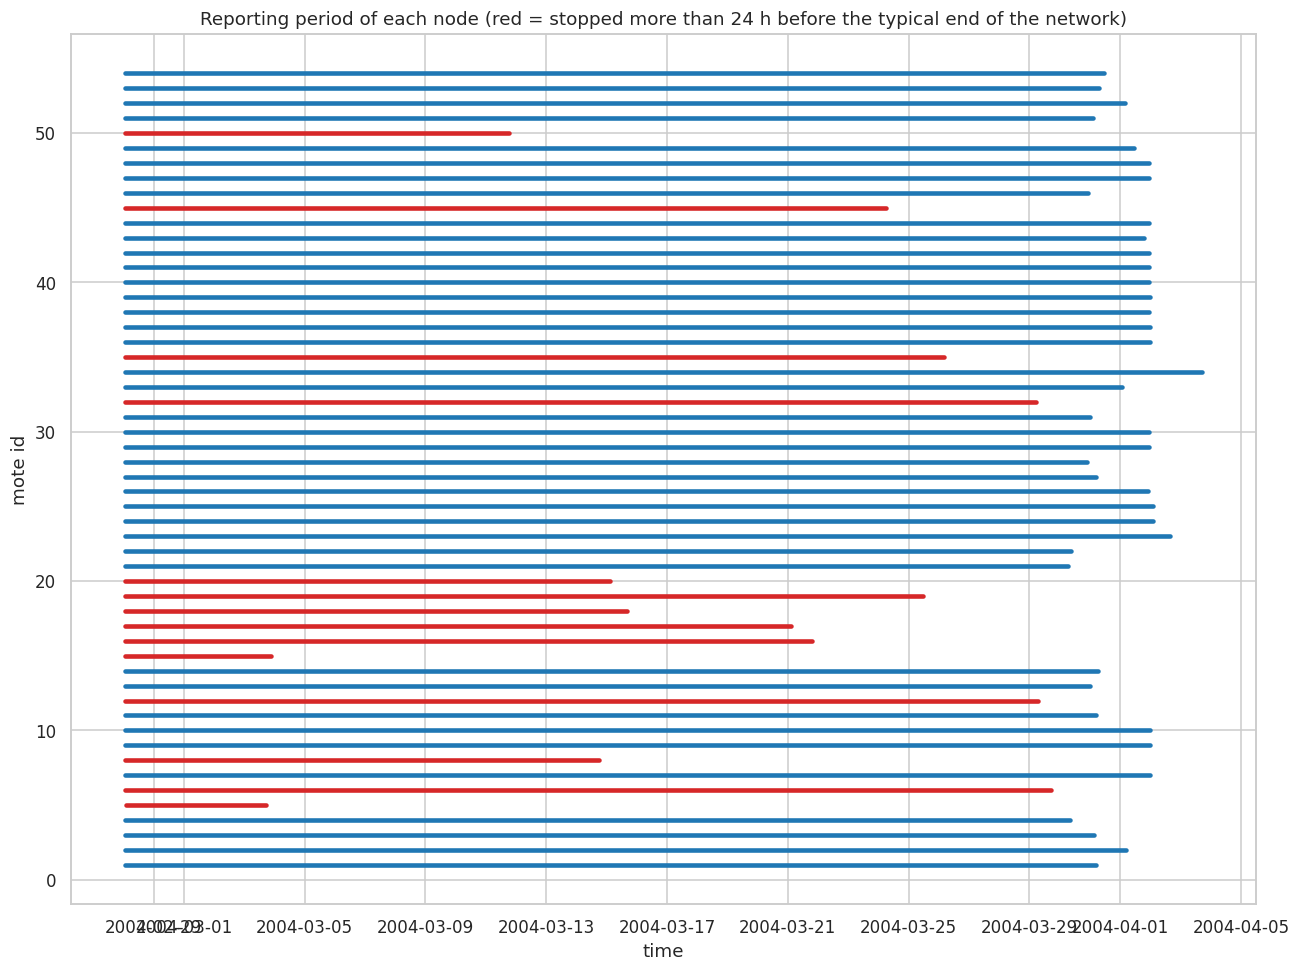

Typical end of the network (median last reading): 2004-03-31 06:34:10.426817536
Nodes that stopped early: 14 of 54


In [ ]:
# Timeline: when does each node report?
fig, ax = plt.subplots(figsize=(12, 9))
for m, r in mote.iterrows():
    ax.plot([r.first_ts, r.last_ts], [m, m], lw=3, color="tab:blue" if r.silence_h <= SILENCE_H else "tab:red")
ax.set_xlabel("time"); ax.set_ylabel("mote id")
ax.set_title(f"Reporting period of each node (red = stopped more than {SILENCE_H} h before the typical end of the network)")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_timeline.png", bbox_inches="tight"); plt.show()
print("Typical end of the network (median last reading):", NET_END)
print("Nodes that stopped early:", int((mote.silence_h > SILENCE_H).sum()), "of", len(mote))

**Observation (to write):** how many nodes stop early? Do they stop at the same time (a network problem) or at different times (node failures)?
Nodes that stop together point to a network or sink problem, not to individual sensor failures.

*Note:* "silent" is measured against the **typical end** of the network (median last reading), not against the last node. Otherwise one node that runs a bit longer would make all others look silent.

## 3. Voltage, temperature and humidity

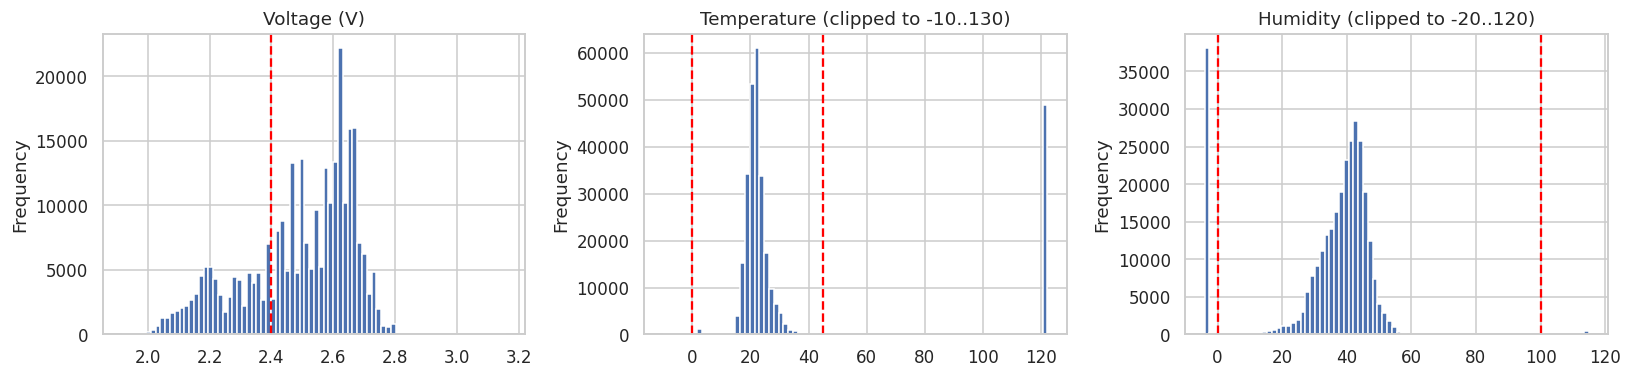

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
sample = df.sample(min(300_000, len(df)), random_state=SEED)
sample.voltage.plot.hist(bins=80, ax=axes[0], title="Voltage (V)")
sample.temperature.clip(-10, 130).plot.hist(bins=80, ax=axes[1], title="Temperature (clipped to -10..130)")
sample.humidity.clip(-20, 120).plot.hist(bins=80, ax=axes[2], title="Humidity (clipped to -20..120)")
for ax, (lo, hi) in zip(axes[1:], [(TEMP_MIN, TEMP_MAX), (HUM_MIN, HUM_MAX)]):
    ax.axvline(lo, color="red", ls="--"); ax.axvline(hi, color="red", ls="--")
axes[0].axvline(V_LOW, color="red", ls="--")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_distributions.png", bbox_inches="tight"); plt.show()

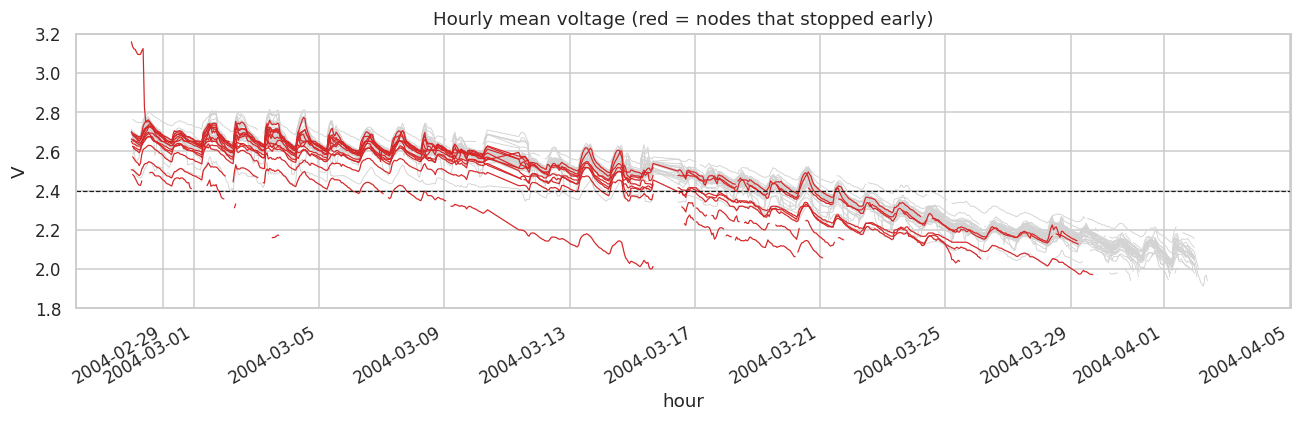

In [ ]:
# Hourly mean voltage of every node (grey) and of the nodes that stopped early (red)
df["hour"] = df.timestamp.dt.floor("h")
volt_h = df.groupby(["hour", "moteid"]).voltage.mean().unstack()
dead_motes = mote.index[mote.silence_h > SILENCE_H]
fig, ax = plt.subplots(figsize=(12, 4))
volt_h.drop(columns=dead_motes, errors="ignore").plot(ax=ax, color="lightgray", legend=False, lw=0.6)
volt_h[[m for m in dead_motes if m in volt_h.columns]].plot(ax=ax, color="tab:red", legend=False, lw=0.8)
ax.axhline(V_LOW, color="k", ls="--", lw=0.8); ax.set_ylim(1.8, 3.2)
ax.set_title("Hourly mean voltage (red = nodes that stopped early)"); ax.set_ylabel("V")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_voltage_all.png", bbox_inches="tight"); plt.show()

**Observation (to write):** does the voltage of the red nodes fall before they stop? Does the dashed line (`V_LOW`) look like a sensible
low-battery level? Do many nodes show impossible temperature or humidity? Adjust the parameters in section 0 if needed and re-run.

## 4. Failure definition
Three kinds of event per node:

| Event | Definition | Used as failure? |
|---|---|---|
| **garbage** | impossible temperature or humidity in at least 50 % of the last 60 readings (a faulty sensor sending nonsense) | yes |
| **silent** | the node stops reporting for good, more than `SILENCE_H` before the typical end of the network | yes (time = its last reading) |
| **lowv** | voltage below `V_LOW` in at least 50 % of the last 60 readings | **no**: it will be a *feature*. Using it as the label would make the voltage trivially predictive |

The failure time of a node is the **earliest** of the chosen events (`FAIL_TYPES`). Nodes without any event are **healthy controls**
(they give us false-alarm estimates).

In [ ]:
bad_garbage = ((df.temperature > TEMP_MAX) | (df.temperature < TEMP_MIN) |
               (df.humidity < HUM_MIN) | (df.humidity > HUM_MAX))
bad_lowv = df.voltage < V_LOW
cnt = df.groupby("moteid").cumcount() + 1

def first_sustained(flag):
    """First time at which >= BAD_FRAC of the last BAD_WINDOW readings of the node are flagged."""
    cum = flag.astype("int32").groupby(df.moteid).cumsum()
    prev = cum.groupby(df.moteid).shift(BAD_WINDOW).fillna(0)
    frac = (cum - prev) / np.minimum(cnt, BAD_WINDOW)
    ok = (frac >= BAD_FRAC) & (cnt >= BAD_WINDOW)
    return df.loc[ok].groupby("moteid").timestamp.min()

mote["t_garbage"] = first_sustained(bad_garbage)
mote["t_lowv"]    = first_sustained(bad_lowv)
mote["t_silent"]  = mote.last_ts.where(mote.silence_h > SILENCE_H)

cand = mote[[f"t_{k}" for k in FAIL_TYPES]]
has = cand.notna().any(axis=1)
mote["t_fail"] = cand.min(axis=1)
mote["fail_type"] = np.where(has, cand.fillna(pd.Timestamp.max).idxmin(axis=1).str.replace("t_", "", regex=False), "healthy")
mote["history_h"] = (mote.t_fail - mote.first_ts) / pd.Timedelta(hours=1)

print(mote.fail_type.value_counts().to_string())
mote.loc[has, ["first_ts", "t_garbage", "t_silent", "t_lowv", "t_fail", "fail_type", "history_h"]].sort_values("t_fail")

fail_type
garbage    50
silent      4


,first_ts,t_garbage,t_silent,t_lowv,t_fail,fail_type,history_h
moteid,,,,,,,
15,2004-02-28 01:07:16.983728,2004-03-02 08:31:30.831185,2004-03-03 20:58:57.887220,2004-03-01 20:04:22.170916,2004-03-02 08:31:30.831185,garbage,79.404
5,2004-02-28 02:21:16.593720,NaT,2004-03-03 17:10:56.993959,NaT,2004-03-03 17:10:56.993959,silent,110.828
18,2004-02-28 00:59:16.711581,2004-03-08 20:05:02.733674,2004-03-15 16:02:37.474513,2004-03-06 01:47:36.812316,2004-03-08 20:05:02.733674,garbage,235.096
50,2004-02-28 01:07:45.989145,NaT,2004-03-11 18:27:40.139660,NaT,2004-03-11 18:27:40.139660,silent,305.332
8,2004-02-28 01:02:16.424892,NaT,2004-03-14 17:53:01.064849,NaT,2004-03-14 17:53:01.064849,silent,376.846
20,2004-02-28 00:58:47.179192,NaT,2004-03-15 02:51:37.365878,NaT,2004-03-15 02:51:37.365878,silent,385.881
17,2004-02-28 01:09:46.166641,2004-03-16 13:54:34.260933,2004-03-21 02:22:24.813249,2004-03-11 18:00:38.639061,2004-03-16 13:54:34.260933,garbage,420.747
16,2004-02-28 01:01:46.422942,2004-03-16 13:55:39.735188,2004-03-21 18:52:30.742254,2004-03-14 19:06:12.648290,2004-03-16 13:55:39.735188,garbage,420.898
35,2004-02-28 01:05:16.224832,2004-03-18 22:58:48.125038,2004-03-26 03:43:06.997200,2004-03-16 11:23:43.125810,2004-03-18 22:58:48.125038,garbage,477.892


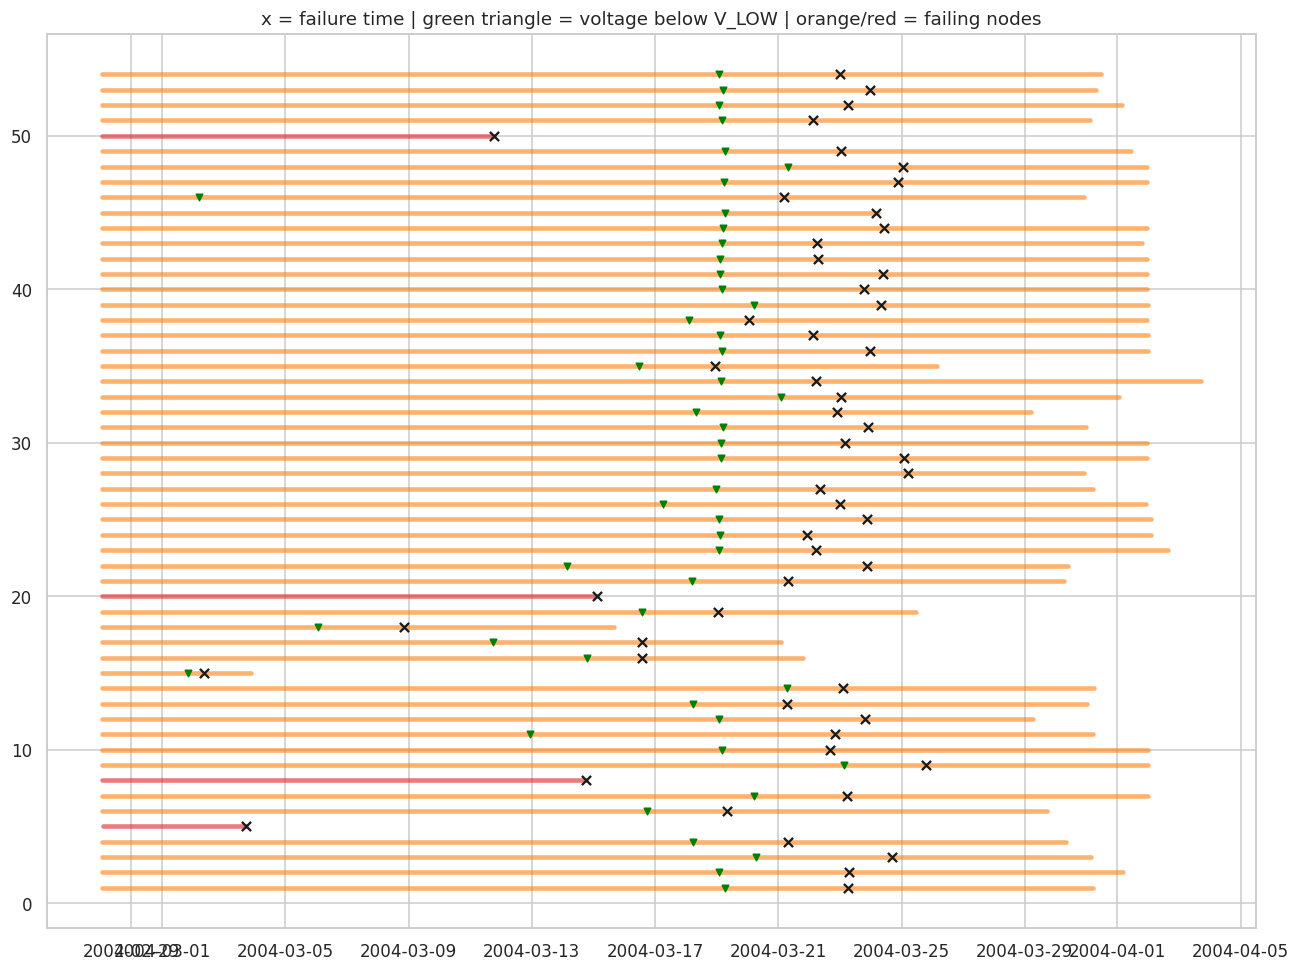

In [ ]:
# Timeline with failure times
fig, ax = plt.subplots(figsize=(12, 9))
col = {"healthy": "tab:blue", "garbage": "tab:orange", "silent": "tab:red"}
for m, r in mote.iterrows():
    ax.plot([r.first_ts, r.last_ts], [m, m], lw=3, color=col.get(r.fail_type, "gray"), alpha=0.6)
    if pd.notna(r.t_fail): ax.scatter([r.t_fail], [m], marker="x", color="k", zorder=3)
    if pd.notna(r.t_lowv): ax.scatter([r.t_lowv], [m], marker="v", color="green", s=18, zorder=3)
ax.set_title("x = failure time | green triangle = voltage below V_LOW | orange/red = failing nodes")
plt.tight_layout(); plt.savefig(FIG_DIR / "04_failures_timeline.png", bbox_inches="tight"); plt.show()

### 4.1 Are the failures independent? How long does the voltage warn?
Two checks that matter for the whole project:
- If many nodes fail within a few days, they share a **common cause** (here: batteries running out together). They are then **not independent events**, and we must say so in the report.
- The time between "voltage below `V_LOW`" and the failure is the **warning time** that a simple voltage rule would give. Our model must beat that rule.

Largest number of failures inside any 5-day window: 42 of 54
Failures per week:
t_fail
2004-03-01/2004-03-07     2
2004-03-08/2004-03-14     3
2004-03-15/2004-03-21    12
2004-03-22/2004-03-28    37
Freq: W-SUN

Voltage fell below V_LOW before the failure for 91 % of failing nodes
Warning time of the simple voltage rule (days between V < V_LOW and failure):
count   49.000
mean     4.220
std      2.730
min      0.520
25%      3.010
50%      3.790
75%      4.750
max     19.000


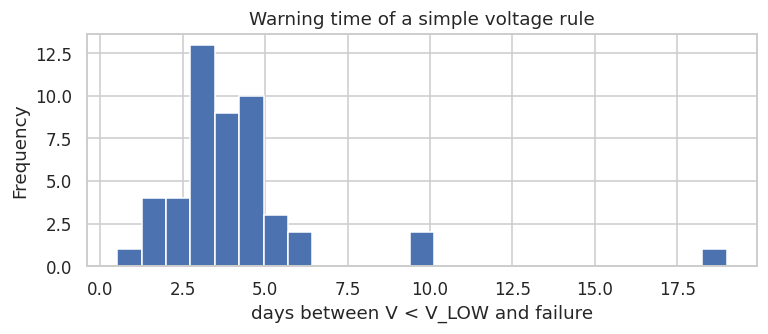

In [ ]:
ft = mote.t_fail.dropna().sort_values()
cluster = max(((ft >= t) & (ft < t + pd.Timedelta(days=5))).sum() for t in ft)
print(f"Largest number of failures inside any 5-day window: {cluster} of {len(ft)}")
print("Failures per week:"); print(ft.dt.to_period("W").value_counts().sort_index().to_string())

lead = ((mote.t_fail - mote.t_lowv) / pd.Timedelta(days=1))[mote.fail_type != "healthy"]
print(f"\nVoltage fell below V_LOW before the failure for {(lead > 0).mean() * 100:.0f} % of failing nodes")
print("Warning time of the simple voltage rule (days between V < V_LOW and failure):")
print(lead[lead > 0].describe().round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 3.2))
lead[lead > 0].plot.hist(bins=25, ax=ax); ax.set_xlabel("days between V < V_LOW and failure"); ax.set_title("Warning time of a simple voltage rule")
plt.tight_layout(); plt.savefig(FIG_DIR / "04b_voltage_rule_lead.png", bbox_inches="tight"); plt.show()

## 5. Feasibility gate (part 1): enough failures?
We need enough failing sensors **with enough history** before the failure to learn from. Otherwise we are back to a handful of events.

In [ ]:
failing = mote[has]
usable = failing[failing.history_h >= MIN_HISTORY_H]
print(f"nodes total: {len(mote)} | failing: {len(failing)} | failing with >= {MIN_HISTORY_H} h of history: {len(usable)} | healthy controls: {int((~has).sum())}")
verdict = "PASS" if len(usable) >= MIN_FAILURES else "FAIL"
print(f"GATE (part 1, need >= {MIN_FAILURES} usable failures): {verdict}")
print(f"Caution: {cluster} of {len(ft)} failures fall in the same 5 days, so they are not independent events (see 4.1).")
failing.fail_type.value_counts().to_frame("failures by type")

nodes total: 54 | failing: 54 | failing with >= 48 h of history: 54 | healthy controls: 0
GATE (part 1, need >= 10 usable failures): PASS
Caution: 42 of 54 failures fall in the same 5 days, so they are not independent events (see 4.1).


,failures by type
fail_type,
garbage,50
silent,4


## 6. Feasibility gate (part 2): is there a precursor?
Many failures are useless if nothing changes before them. We look at three signals before the failure:
**voltage**, **reporting rate** (a bad connection often comes first) and **temperature noise**.

Compare the failing nodes (aligned on the failure time) with control windows taken from healthy nodes and from the failing nodes' own healthy past.

In [ ]:
# Hourly table per node
H = (df.groupby(["moteid", "hour"])
       .agg(voltage=("voltage", "mean"), temp_std=("temperature", "std"), n=("moteid", "size")).reset_index())
H["coverage"] = (H.n / EXPECTED_PER_H).clip(upper=1.5)
HM = {m: g.set_index("hour") for m, g in H.groupby("moteid")}

rng = np.random.default_rng(SEED)
def random_ends(m, lo, hi, k):
    """k random whole-hour times between lo and hi."""
    if hi <= lo: return []
    hours = int((hi - lo) / pd.Timedelta(hours=1))
    return [lo.ceil("h") + pd.Timedelta(hours=int(h)) for h in rng.integers(0, max(hours, 1), k)]

def aligned(m, ref, hours=168):
    idx = pd.date_range(ref - pd.Timedelta(hours=hours), ref, freq="h")
    w = HM[m].reindex(idx)
    return pd.DataFrame({"rel_h": (idx - ref) / pd.Timedelta(hours=1), "voltage": w.voltage.values,
                         "coverage": w.coverage.fillna(0).values, "temp_std": w.temp_std.values, "mote": m})

pos_curves, ctl_curves = [], []
for m, r in usable.iterrows():
    pos_curves.append(aligned(m, r.t_fail.floor("h")))
for m, r in mote.iterrows():
    hi = (r.t_fail - pd.Timedelta(hours=72)) if pd.notna(r.t_fail) else r.last_ts
    for e in random_ends(m, r.first_ts + pd.Timedelta(hours=168), hi, 15):
        ctl_curves.append(aligned(m, e))
P = pd.concat(pos_curves) if pos_curves else pd.DataFrame()
Cc = pd.concat(ctl_curves) if ctl_curves else pd.DataFrame()
print("failure curves:", P.mote.nunique() if len(P) else 0, "nodes | control windows:", len(ctl_curves))

failure curves: 54 nodes | control windows: 765


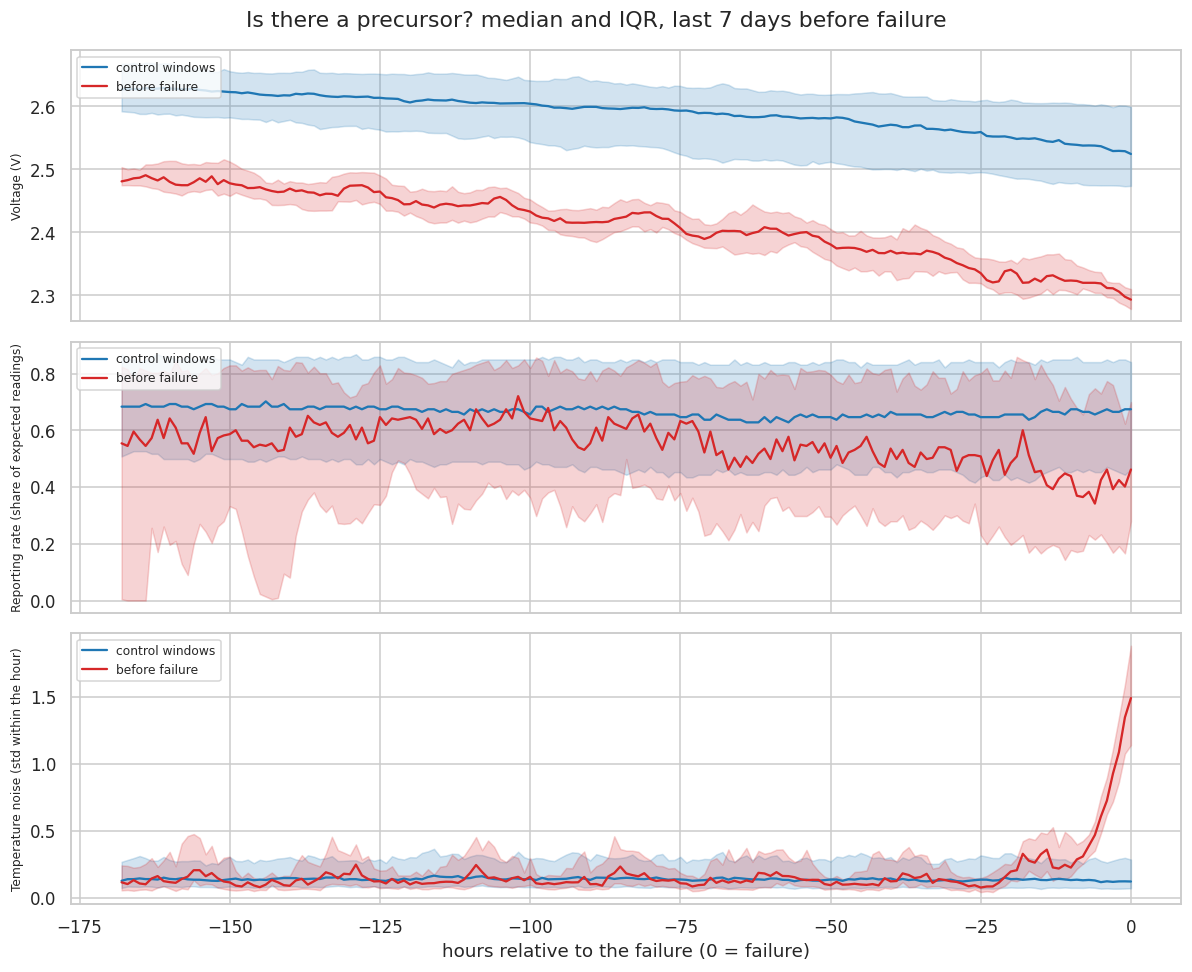

In [ ]:
sig = [("voltage", "Voltage (V)"), ("coverage", "Reporting rate (share of expected readings)"), ("temp_std", "Temperature noise (std within the hour)")]
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for ax, (c, title) in zip(axes, sig):
    for D, lab, colr in [(Cc, "control windows", "tab:blue"), (P, "before failure", "tab:red")]:
        if not len(D): continue
        q = D.groupby("rel_h")[c].quantile([0.25, 0.5, 0.75]).unstack()
        ax.plot(q.index, q[0.5], color=colr, label=lab); ax.fill_between(q.index, q[0.25], q[0.75], color=colr, alpha=0.2)
    ax.set_ylabel(title, fontsize=8); ax.legend(loc="upper left", fontsize=8)
axes[-1].set_xlabel("hours relative to the failure (0 = failure)")
plt.suptitle("Is there a precursor? median and IQR, last 7 days before failure")
plt.tight_layout(); plt.savefig(FIG_DIR / "05_precursor.png", bbox_inches="tight"); plt.show()

In [ ]:
# Single-feature AUC: windows of 24 h ending LEAD hours before the failure (positives) vs control windows. 0.5 = no signal.
def window_feats(m, end, length_h=24):
    idx = pd.date_range(end - pd.Timedelta(hours=length_h), end, freq="h", inclusive="left")
    w = HM[m].reindex(idx)
    v = w.voltage
    ok = v.notna().values
    slope = np.polyfit(np.arange(length_h)[ok], v.values[ok], 1)[0] * 24 if ok.sum() >= 12 else np.nan
    return {"voltage_mean": v.mean(), "voltage_slope_per_day": slope,
            "reporting_rate": w.coverage.fillna(0).mean(), "temp_noise": w.temp_std.mean()}

ctrl = []
for m, r in mote.iterrows():
    hi = (r.t_fail - pd.Timedelta(hours=72)) if pd.notna(r.t_fail) else r.last_ts
    for e in random_ends(m, r.first_ts + pd.Timedelta(hours=24), hi, 30):
        ctrl.append(window_feats(m, e))
ctrl = pd.DataFrame(ctrl)

rows = []
for lead in [6, 24, 48]:
    pos = pd.DataFrame([window_feats(m, r.t_fail.floor("h") - pd.Timedelta(hours=lead))
                        for m, r in usable.iterrows()
                        if r.t_fail.floor("h") - pd.Timedelta(hours=lead + 24) >= r.first_ts])
    for f in ctrl.columns:
        a = pos[f].dropna() if len(pos) else pd.Series(dtype=float); b = ctrl[f].dropna()
        auc = roc_auc_score(np.r_[np.ones(len(a)), np.zeros(len(b))], np.r_[a.values, b.values]) if len(a) >= 5 and len(b) > 0 else np.nan
        rows.append({"lead_h": lead, "feature": f, "n_failures": len(a), "AUC": auc})
auc_tab = pd.DataFrame(rows).pivot(index="feature", columns="lead_h", values="AUC")
print("AUC of one feature at a time. 0.5 = no signal, far from 0.5 (either side) = some signal.")
auc_tab

AUC of one feature at a time. 0.5 = no signal, far from 0.5 (either side) = some signal.


lead_h,6,24,48
feature,,,
reporting_rate,0.360,0.390,0.387
temp_noise,0.539,0.364,0.425
voltage_mean,0.012,0.020,0.036
voltage_slope_per_day,0.411,0.419,0.495


**How to read the gate (part 2)**
- In the plots, a precursor shows as the red curve moving away from the blue curve **before** hour 0.
- In the AUC table, values near 0.5 at 6 h, 24 h and 48 h mean no precursor in these three signals. Values clearly away from 0.5 (for example above 0.7 or below 0.3) are promising.
- With only a few failing nodes the AUC is noisy: look at `n_failures` and do not over-read small differences.
- **Decision rule:** continue to notebook 02 if part 1 passes **and** at least one signal separates clearly at 24 h or more.
  If failures are plentiful but there is no precursor, we continue with fault *detection* of the sensors and say honestly that early warning is not supported.
  If failures are too few, we stop and choose another option.

## 7. Save for the next notebook

In [ ]:
clean = df.drop(columns=["hour"])
clean.to_parquet(PROC_DIR / "intel_clean.parquet")
mote.to_csv(PROC_DIR / "mote_status.csv")
H.to_parquet(PROC_DIR / "hourly.parquet")

meta = {"fail_types": FAIL_TYPES, "silence_h": SILENCE_H, "temp_range": [TEMP_MIN, TEMP_MAX], "humidity_range": [HUM_MIN, HUM_MAX],
        "v_low": V_LOW, "bad_window": BAD_WINDOW, "bad_frac": BAD_FRAC, "median_interval_s": MED_DT.total_seconds(),
        "end": str(END), "network_end": str(NET_END), "n_motes": int(len(mote)), "n_failing": int(has.sum()), "n_usable_failures": int(len(usable))}
(PROC_DIR / "failure_definition.json").write_text(json.dumps(meta, indent=2))
print(json.dumps(meta, indent=2))

{
  "fail_types": [
    "garbage",
    "silent"
  ],
  "silence_h": 24,
  "temp_range": [
    0,
    45
  ],
  "humidity_range": [
    0,
    100
  ],
  "v_low": 2.4,
  "bad_window": 60,
  "bad_frac": 0.5,
  "median_interval_s": 33.244021,
  "end": "2004-04-03 16:51:34.171452",
  "network_end": "2004-03-31 06:34:10.426817536",
  "n_motes": 54,
  "n_failing": 54,
  "n_usable_failures": 54
}
